--- Multi-Branch Dataset Ready (Natural Distribution) ---
Merged shape: (30000, 14)

Target Class Distribution:
0    28992
1     1008
Name: count, dtype: int64
Positive Class Ratio: 3.36%
Train fit split balanced to 50/50: 1210 rows (605 pos / 605 neg) | Val & Test kept at natural imbalance

--- Model Comparison (Balanced Train, Natural Val/Test Imbalance) ---
            model  val_thr  test_prec  test_rec  test_f1  test_roc_auc  test_pr_auc  test_acc
   LogReg (C=0.1)   0.9342     0.4480    0.4901   0.4681        0.9407       0.3531    0.9625
   LogReg (C=1.0)   0.9374     0.4476    0.5495   0.4933        0.9440       0.3542    0.9620
   LogReg (C=5.0)   0.9505     0.4167    0.5198   0.4626        0.9437       0.3467    0.9593
LinearSVC (C=1.0)   0.8661     0.3872    0.5693   0.4609        0.9422       0.3306    0.9552

--- False Positive Linguistic Audit (FPs=137) ---
             feature  fp_mean  tn_mean  fp_vs_tn_ratio
     avg_word_length   5.6259   5.3799            1.05
     u

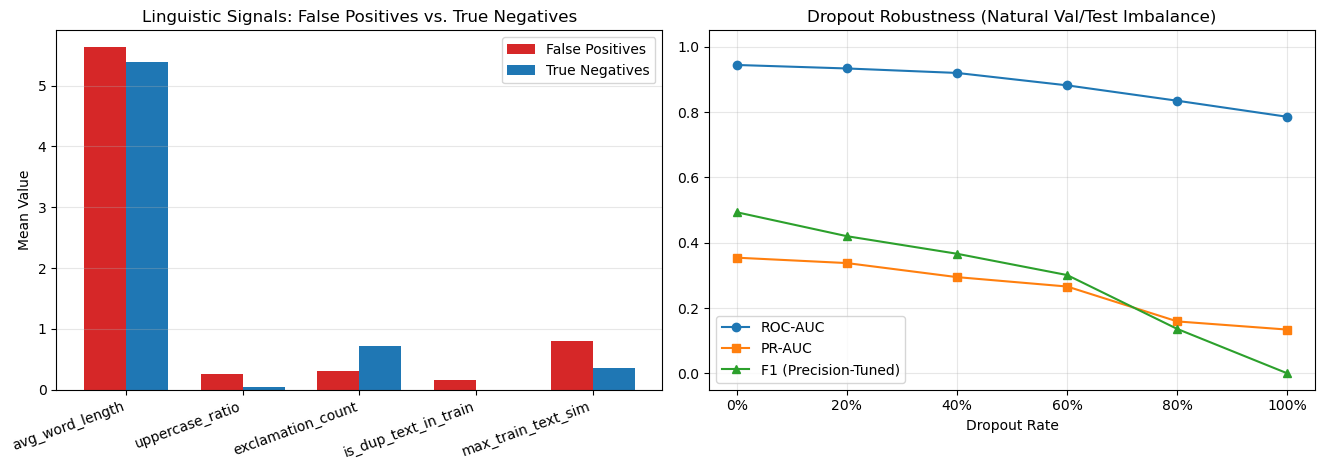


Final Accuracy (LogReg (C=1.0)): 0.9620 (96.20%)


In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

review_path = r"C:\Users\rnu43\MyFiles\Documents\Python\PROJECTS\FRD_System\All_Beauty.jsonl\All_Beauty.jsonl"
meta_path = r"C:\Users\rnu43\MyFiles\Documents\Python\PROJECTS\FRD_System\meta_All_Beauty.jsonl\meta_All_Beauty.jsonl"

# Increase nrows (e.g. 30000) or set nrows=None to load all reviews
N_ROWS = 30000

# 1. Load reviews and stream metadata in chunks matching parent_asin
reviews_df = pd.read_json(review_path, lines=True, nrows=N_ROWS)

target_asins = set(reviews_df["parent_asin"].dropna().unique())
matched_meta = []

for chunk in pd.read_json(meta_path, lines=True, chunksize=10000):
  sub = chunk[chunk["parent_asin"].isin(target_asins)][
      ["parent_asin", "price", "average_rating", "rating_number", "store"]
  ]
  if not sub.empty:
    matched_meta.append(sub)

meta_matched_df = (
    pd.concat(matched_meta, ignore_index=True)
    if matched_meta
    else pd.DataFrame(
        columns=["parent_asin", "price", "average_rating", "rating_number", "store"]
    )
).drop_duplicates(subset=["parent_asin"])

merged_df = pd.merge(
    reviews_df, meta_matched_df, on="parent_asin", how="left"
).reset_index(drop=True)

print("--- Multi-Branch Dataset Ready (Natural Distribution) ---")
print(f"Merged shape: {merged_df.shape}")

# 2. Text & non-circular features (avoiding target leakage from heuristic inputs)
merged_df["clean_text"] = (
    merged_df["title"].fillna("").astype(str)
    + " "
    + merged_df["text"].fillna("").astype(str)
).str.strip()

merged_df["norm_text"] = (
    merged_df["clean_text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Heuristic-only helpers (kept out of X to prevent circular labeling)
_char_count = merged_df["clean_text"].str.len().astype(float)
_word_count = merged_df["clean_text"].str.split().str.len().astype(float)
_is_extreme_rating = merged_df["rating"].isin([1, 5]).astype(int)
_verified_purchase = merged_df["verified_purchase"].fillna(False).astype(int)
_helpful_vote = pd.to_numeric(merged_df["helpful_vote"], errors="coerce").fillna(0)
_user_counts = merged_df["user_id"].map(merged_df["user_id"].value_counts())
_is_cold_start_user = (_user_counts == 1).astype(int)

# Non-circular stylometric & item-context features (short reviews retained)
merged_df["avg_word_length"] = _char_count / (_word_count + 1e-5)
merged_df["uppercase_ratio"] = merged_df["clean_text"].apply(
    lambda x: sum(1 for c in x if c.isupper()) / (len(x) + 1e-5)
)
merged_df["exclamation_count"] = merged_df["clean_text"].apply(
    lambda x: x.count("!")
)

merged_df["price_is_missing"] = merged_df["price"].isna().astype(int)
merged_df["store_is_missing"] = merged_df["store"].isna().astype(int)
merged_df["price_cleaned"] = pd.to_numeric(merged_df["price"], errors="coerce")
merged_df["average_rating_num"] = pd.to_numeric(
    merged_df["average_rating"], errors="coerce"
)
merged_df["rating_number_num"] = pd.to_numeric(
    merged_df["rating_number"], errors="coerce"
)
merged_df["rating_diff_from_avg"] = (
    pd.to_numeric(merged_df["rating"], errors="coerce")
    - merged_df["average_rating_num"]
)

# 3. Weak-supervision heuristic target y (strictly separate from features X)
cond1 = (
    (_is_extreme_rating == 1) & (_verified_purchase == 0) & (_helpful_vote == 0)
)
cond2 = (
    (_is_extreme_rating == 1)
    & (_is_cold_start_user == 1)
    & (_char_count < 40)
)
cond3 = (_is_extreme_rating == 1) & (_word_count < 5)

score = cond1.astype(int) + cond2.astype(int) + cond3.astype(int)
y = (score >= 2).astype(int)

print(
    f"\nTarget Class Distribution:\n{y.value_counts()}\nPositive Class Ratio:"
    f" {y.mean() * 100:.2f}%"
)

# 4. Leak-free Train / Validation / Test split (60% train, 20% val, 20% test)
indices = np.arange(len(merged_df))
train_full_idx, test_idx = train_test_split(
    indices, test_size=0.20, random_state=42, stratify=y
)
train_idx, val_idx = train_test_split(
    train_full_idx,
    test_size=0.25,
    random_state=42,
    stratify=y.iloc[train_full_idx],
)

# Balance ONLY train_idx to 50/50; keep val_idx and test_idx at natural imbalance
rng = np.random.default_rng(42)
y_train_full = y.iloc[train_idx].to_numpy()
pos_tr_local = np.where(y_train_full == 1)[0]
neg_tr_local = np.where(y_train_full == 0)[0]
n_per_tr = min(len(pos_tr_local), len(neg_tr_local))

sampled_pos_tr = rng.choice(pos_tr_local, size=n_per_tr, replace=False)
sampled_neg_tr = rng.choice(neg_tr_local, size=n_per_tr, replace=False)
balanced_tr_order = rng.permutation(
    np.concatenate([sampled_pos_tr, sampled_neg_tr])
)
train_fit_idx = train_idx[balanced_tr_order]

print(
    f"Train fit split balanced to 50/50: {len(train_fit_idx)} rows "
    f"({n_per_tr} pos / {n_per_tr} neg) | Val & Test kept at natural imbalance"
)

train_norm_texts = set(merged_df.iloc[train_fit_idx]["norm_text"])
train_norm_texts.discard("")
merged_df["is_dup_text_in_train"] = (
    merged_df["norm_text"].isin(train_norm_texts).astype(int)
)

tfidf = TfidfVectorizer(
    max_features=8000, ngram_range=(1, 2), stop_words="english"
)
X_text_train = tfidf.fit_transform(merged_df.iloc[train_fit_idx]["clean_text"])
X_text_val = tfidf.transform(merged_df.iloc[val_idx]["clean_text"])
X_text_test = tfidf.transform(merged_df.iloc[test_idx]["clean_text"])

train_sim_mat = cosine_similarity(X_text_train, X_text_train)
np.fill_diagonal(train_sim_mat, 0.0)
max_sim_col = np.zeros(len(merged_df), dtype=float)
max_sim_col[train_fit_idx] = train_sim_mat.max(axis=1)
max_sim_col[val_idx] = cosine_similarity(X_text_val, X_text_train).max(axis=1)
max_sim_col[test_idx] = cosine_similarity(X_text_test, X_text_train).max(axis=1)
merged_df["max_train_text_sim"] = max_sim_col

feature_cols = [
    "avg_word_length",
    "uppercase_ratio",
    "exclamation_count",
    "price_is_missing",
    "store_is_missing",
    "price_cleaned",
    "average_rating_num",
    "rating_number_num",
    "rating_diff_from_avg",
    "is_dup_text_in_train",
    "max_train_text_sim",
]

dense_df = merged_df[feature_cols].copy()
impute_cols = [
    "price_cleaned",
    "average_rating_num",
    "rating_number_num",
    "rating_diff_from_avg",
]
for col in impute_cols:
  med = dense_df.iloc[train_fit_idx][col].median()
  dense_df[col] = dense_df[col].fillna(0.0 if pd.isna(med) else med)

scaler = StandardScaler()
X_dense_train = scaler.fit_transform(dense_df.iloc[train_fit_idx])
X_dense_val = scaler.transform(dense_df.iloc[val_idx])
X_dense_test = scaler.transform(dense_df.iloc[test_idx])

X_train = hstack([X_text_train, csr_matrix(X_dense_train)]).tocsr()
X_val = hstack([X_text_val, csr_matrix(X_dense_val)]).tocsr()
X_test_base = hstack([X_text_test, csr_matrix(X_dense_test)]).tocsr()

y_train = y.iloc[train_fit_idx].to_numpy()
y_val = y.iloc[val_idx].to_numpy()
y_test = y.iloc[test_idx].to_numpy()


def tune_threshold_precision_aware(
    y_true_val, scores_val, target_precision=0.35, min_recall=0.35
):
  """Choose threshold maximizing F1 among points meeting target_precision and min_recall."""
  precisions, recalls, thresholds = precision_recall_curve(y_true_val, scores_val)
  if len(thresholds) == 0:
    return 0.5, np.array([0.0]), np.array([0.5])
  p, r = precisions[:-1], recalls[:-1]
  f1s = 2 * (p * r) / (p + r + 1e-8)

  strict = np.where((p >= target_precision) & (r >= min_recall))[0]
  if len(strict) > 0:
    best_i = strict[np.argmax(f1s[strict])]
  else:
    prec_only = np.where(p >= target_precision)[0]
    if len(prec_only) > 0:
      best_i = prec_only[np.argmax(f1s[prec_only])]
    else:
      best_i = int(np.argmax(p))
  return float(thresholds[best_i]), f1s, thresholds


# 5. Model tuning & comparison: LogisticRegression (C) vs LinearSVC
candidates = [
    (
        "LogReg (C=0.1)",
        LogisticRegression(
            C=0.1, class_weight="balanced", max_iter=2000, random_state=42
        ),
    ),
    (
        "LogReg (C=1.0)",
        LogisticRegression(
            C=1.0, class_weight="balanced", max_iter=2000, random_state=42
        ),
    ),
    (
        "LogReg (C=5.0)",
        LogisticRegression(
            C=5.0, class_weight="balanced", max_iter=2000, random_state=42
        ),
    ),
    (
        "LinearSVC (C=1.0)",
        LinearSVC(
            C=1.0,
            class_weight="balanced",
            dual="auto",
            tol=1e-3,
            max_iter=20000,
            random_state=42,
        ),
    ),
]

comp_rows = []
models_info = {}

for name, clf in candidates:
  clf.fit(X_train, y_train)
  val_s = (
      clf.predict_proba(X_val)[:, 1]
      if hasattr(clf, "predict_proba")
      else clf.decision_function(X_val)
  )
  test_s = (
      clf.predict_proba(X_test_base)[:, 1]
      if hasattr(clf, "predict_proba")
      else clf.decision_function(X_test_base)
  )

  thr, f1_c, thr_c = tune_threshold_precision_aware(
      y_val, val_s, target_precision=0.35, min_recall=0.35
  )
  pred_t = (test_s >= thr).astype(int)

  comp_rows.append({
      "model": name,
      "val_thr": round(thr, 4),
      "test_prec": round(precision_score(y_test, pred_t, zero_division=0), 4),
      "test_rec": round(recall_score(y_test, pred_t, zero_division=0), 4),
      "test_f1": round(f1_score(y_test, pred_t), 4),
      "test_roc_auc": round(roc_auc_score(y_test, test_s), 4),
      "test_pr_auc": round(average_precision_score(y_test, test_s), 4),
      "test_acc": round(accuracy_score(y_test, pred_t), 4),
  })
  models_info[name] = {
      "clf": clf,
      "thr": thr,
      "test_scores": test_s,
      "test_pred": pred_t,
      "f1_curve": f1_c,
      "thr_curve": thr_c,
  }

comp_df = pd.DataFrame(comp_rows)
print(
    "\n--- Model Comparison (Balanced Train, Natural Val/Test Imbalance) ---"
)
print(comp_df.to_string(index=False))

best_name = comp_df.sort_values(
    ["test_f1", "test_prec"], ascending=False
).iloc[0]["model"]
best = models_info[best_name]
model = best["clf"]
best_threshold = best["thr"]
y_prob = best["test_scores"]
y_pred_tuned = best["test_pred"]

# 6. False Positive Linguistic Feature Audit
fp_mask = (y_test == 0) & (y_pred_tuned == 1)
tn_mask = (y_test == 0) & (y_pred_tuned == 0)
fp_df_indices = test_idx[fp_mask]
tn_df_indices = test_idx[tn_mask]
fp_scores = y_prob[fp_mask]

linguistic_cols = [
    "avg_word_length",
    "uppercase_ratio",
    "exclamation_count",
    "is_dup_text_in_train",
    "max_train_text_sim",
]
fp_means = merged_df.iloc[fp_df_indices][linguistic_cols].mean()
tn_means = merged_df.iloc[tn_df_indices][linguistic_cols].mean()

audit_df = pd.DataFrame({
    "feature": linguistic_cols,
    "fp_mean": fp_means.round(4).values,
    "tn_mean": tn_means.round(4).values,
    "fp_vs_tn_ratio": (fp_means / (tn_means + 1e-6)).round(2).values,
})
print(f"\n--- False Positive Linguistic Audit (FPs={len(fp_df_indices)}) ---")
print(audit_df.to_string(index=False))

# Top TF-IDF terms contributing to positive predictions among False Positives
feature_names = np.array(list(tfidf.get_feature_names_out()) + feature_cols)
coefs = model.coef_[0]
n_text = X_text_train.shape[1]
text_coefs = coefs[:n_text]

if len(fp_df_indices) > 0:
  fp_tfidf_mean = np.asarray(X_text_test[fp_mask].mean(axis=0)).ravel()
  fp_term_impact = fp_tfidf_mean * text_coefs
  top_fp_terms_idx = np.argsort(-fp_term_impact)[:10]
  top_terms = [
      (feature_names[i], round(float(fp_term_impact[i]), 4))
      for i in top_fp_terms_idx
      if fp_term_impact[i] > 0
  ]
  print("Top positive-weighted TF-IDF terms active in FPs:", top_terms)

print("\n--- Top False Positive Examples ---")
for rank, pos in enumerate(np.argsort(-fp_scores)[:10], start=1):
  row_i = fp_df_indices[pos]
  r = merged_df.iloc[row_i]
  snip = r["clean_text"][:130].replace("\n", " ")
  print(
      f"[{rank}] score={fp_scores[pos]:.4f} | rating={r['rating']} |"
      f" verified={int(_verified_purchase.iloc[row_i])} |"
      f" words={int(_word_count.iloc[row_i])} |"
      f" caps={r['uppercase_ratio']:.2f} | excl={int(r['exclamation_count'])} |"
      f" dup={int(r['is_dup_text_in_train'])} | sim={r['max_train_text_sim']:.2f}"
      f" | text=\"{snip}\""
  )

# 7. Metadata dropout evaluation
rng_drop = np.random.default_rng(42)
dropout_rates = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
results = []

for rate in dropout_rates:
  X_masked = X_test_base.tolil()
  dense_block = X_masked[:, n_text:].toarray()

  if rate > 0:
    mask = rng_drop.random(dense_block.shape) < rate
    dense_block[mask] = 0.0

  X_masked[:, n_text:] = dense_block
  X_eval = X_masked.tocsr()

  probs = (
      model.predict_proba(X_eval)[:, 1]
      if hasattr(model, "predict_proba")
      else model.decision_function(X_eval)
  )
  preds_tun = (probs >= best_threshold).astype(int)

  results.append({
      "dropout_rate": f"{int(rate * 100)}%",
      "f1": round(f1_score(y_test, preds_tun), 4),
      "roc_auc": round(roc_auc_score(y_test, probs), 4),
      "pr_auc": round(average_precision_score(y_test, probs), 4),
  })

results_df = pd.DataFrame(results)
print("\n--- Metadata Dropout Results ---")
print(results_df.to_string(index=False))

# 8. Plots: FP Linguistic Comparison & Dropout Curve
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

x_l = np.arange(len(audit_df))
axes[0].bar(
    x_l - 0.18, audit_df["fp_mean"], width=0.36, label="False Positives", color="tab:red"
)
axes[0].bar(
    x_l + 0.18, audit_df["tn_mean"], width=0.36, label="True Negatives", color="tab:blue"
)
axes[0].set_xticks(x_l)
axes[0].set_xticklabels(audit_df["feature"], rotation=20, ha="right")
axes[0].set_title("Linguistic Signals: False Positives vs. True Negatives")
axes[0].set_ylabel("Mean Value")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

x_d = np.arange(len(results_df))
axes[1].plot(x_d, results_df["roc_auc"], marker="o", label="ROC-AUC")
axes[1].plot(x_d, results_df["pr_auc"], marker="s", label="PR-AUC")
axes[1].plot(x_d, results_df["f1"], marker="^", label="F1 (Precision-Tuned)")
axes[1].set_xticks(x_d)
axes[1].set_xticklabels(results_df["dropout_rate"])
axes[1].set_title("Dropout Robustness (Natural Val/Test Imbalance)")
axes[1].set_xlabel("Dropout Rate")
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

final_acc = accuracy_score(y_test, y_pred_tuned)
print(
    f"\nFinal Accuracy ({best_name}): {final_acc:.4f} ({final_acc * 100:.2f}%)"
)